# Sparse Identification of Nonlinear Socio-Technical Dynamics (SocioSINDy)

### Load libaries

In [31]:
import pysindy as ps
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

In [32]:
# ignore user warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### Set initial conditions of dataset

In [33]:
dt = 1 # timestep size
sample_length = 9 # length of one simulation

n_ics = 27 # number of individual simulations
x_train = [np.zeros((sample_length, 6)) for i in range(n_ics)] # create list of empty arrays

### Load dataset

In [34]:
data = pd.read_csv("safety_barriers.csv", delimiter=";", decimal=",") # load dataset from csv file
data = data.drop(columns=['t']) # drop "t" column
data.head()

,Communication reliability (Dmnl),Stable zero enforcement time (seconds),Stable zero enforcement effectivess (Dmnl),"Residual gas discovery, pending vent",Probability of error generation,Residual gas in hydrogen tank
0,0.9,5,0.9,0.000000,0.293718,0.356115
1,0.9,5,0.9,0.000000,0.389030,0.460712
2,0.9,5,0.9,0.000000,0.463863,0.599252
3,0.9,5,0.9,0.624150,0.807010,0.764441
4,0.9,5,0.9,0.234647,0.536306,0.287388


In [35]:
data_np = data.to_numpy(dtype="float") # convert dataframe to numpy array

In [36]:
# fill empty list of arrays with values from loaded dataset
for idx in range(n_ics):
    x_train[idx][:] = data_np[(idx*sample_length):((idx*sample_length)+sample_length), :]

In [37]:
# scale the second column (index 1) from 0 to 1
for idx in range(n_ics):
    x_train[idx][:, 1] = (x_train[idx][:, 1] - 0) / (5 - 0)

### Split dataset into control features and input features

In [38]:
u_train = [x_train[i][:, :3] for i in range(n_ics)] # control features
x_train = [x_train[i][:, 3:] for i in range(n_ics)] # input features

### Create bootstrap function

In [39]:
def create_bootstrap_subsets(input_features, control_features, n_subsets=20, test_size=0.2, random_seed=42):
    """
    create multiple bootstrap subsets (sampling with replacement)
    """
    np.random.seed(random_seed)
    subsets = []
    n_total = len(input_features)
    n_test = int(test_size * n_total)  # Size of OOB (out-of-bag) sample
    
    for subset_num in range(n_subsets):
        # bootstrap sample: sample WITH replacement for training
        train_idx = np.random.choice(n_total, size=n_total, replace=True)
        
        # Out-of-bag (OOB) sample: indices not in bootstrap sample for testing
        all_indices = set(range(n_total))
        bootstrap_indices = set(train_idx)
        test_idx = np.array(list(all_indices - bootstrap_indices))
        
        if len(test_idx) < n_test: # if OOB sample is too small, randomly select test samples
            # get additional random indices for testing
            remaining = np.array(list(all_indices - set(test_idx)))
            additional = np.random.choice(remaining, size=n_test-len(test_idx), replace=False)
            test_idx = np.concatenate([test_idx, additional])
        
        train_data = [input_features[i] for i in train_idx]
        u_train_data = [control_features[i] for i in train_idx]
        
        # for test data, use the original order (without replacement)
        test_data = [input_features[i] for i in test_idx] if len(test_idx) > 0 else []
        u_test_data = [control_features[i] for i in test_idx] if len(test_idx) > 0 else []
        
        subsets.append({
            'subset_num': subset_num,
            'train_indices': train_idx,  # NOTE: has duplicates due to replacement
            'test_indices': test_idx,    # OOB sample
            'train_data': train_data,
            'test_data': test_data,
            'u_train_data': u_train_data,
            'u_test_data': u_test_data,
            'bootstrap_duplicates': len(train_idx) - len(set(train_idx))  # ccount of duplicates
        })
        
        print(f"\nBootstrap subset {subset_num + 1}:")
        print(f"  Train subsets: {len(train_idx)} (with replacement)")
        print(f"  Unique train subsets: {len(set(train_idx))}")
        print(f"  Test subsets (OOB): {len(test_idx)}")
    
    return subsets

### Generate bootstrap subsets

In [40]:
n_subsets = 200 # number of subsets
test_size = 0.2 # percentage of test size

subsets = create_bootstrap_subsets(input_features=x_train, control_features=u_train, n_subsets=200, test_size=test_size) # call function


Bootstrap subset 1:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 2:
  Train subsets: 27 (with replacement)
  Unique train subsets: 19
  Test subsets (OOB): 8

Bootstrap subset 3:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 4:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 5:
  Train subsets: 27 (with replacement)
  Unique train subsets: 16
  Test subsets (OOB): 11

Bootstrap subset 6:
  Train subsets: 27 (with replacement)
  Unique train subsets: 15
  Test subsets (OOB): 12

Bootstrap subset 7:
  Train subsets: 27 (with replacement)
  Unique train subsets: 19
  Test subsets (OOB): 8

Bootstrap subset 8:
  Train subsets: 27 (with replacement)
  Unique train subsets: 18
  Test subsets (OOB): 9

Bootstrap subset 9:
  Train subsets: 27 (with replacement)
  Unique train subsets: 15
  Test subsets (OOB)

### Create confidence interval function

In [41]:
def calculate_confidence(scores, confidence=0.95):
    """
    calculate confidence interval from bootstrap scores
    """
    alpha = 1 - confidence
    lower_percentile = (alpha / 2) * 100
    upper_percentile = (1 - alpha / 2) * 100
    
    ci_lower = np.percentile(scores, lower_percentile)
    ci_upper = np.percentile(scores, upper_percentile)
    
    return ci_lower, ci_upper

### Initiate DiscreteSINDy model

In [84]:
threshold = 0.5
degree=2

optimizer = ps.STLSQ(threshold=threshold, normalize_columns=True)
library = ps.PolynomialLibrary(degree=degree, interaction_only=False)
model = ps.DiscreteSINDy(optimizer=optimizer, feature_library=library)

### Fit and evaluate model

In [85]:
r2_score = []
mse_score = []
for subset in range(len(subsets)):
    model.fit(subsets[subset]["train_data"], t=dt, u=subsets[subset]["u_train_data"])
    if subset % 50 == 0:
        model.print()
        print("\n")
    r2_score.append(model.score(subsets[subset]["test_data"], t=dt, u=subsets[subset]["u_test_data"]))
    mse_score.append(model.score(subsets[subset]["test_data"], t=dt, u=subsets[subset]["u_test_data"], metric=mean_squared_error))
    #print(model.score(splits[split]["test_data"], t=dt, u=splits[split]["u_test_data"], metric=mean_squared_error))
    
ci_lower_r2, ci_upper_r2 = calculate_confidence(r2_score, confidence=0.95) # confidence interval for r2 score
print(f"95% Confidence Interval for R^2 score: [{ci_lower_r2:.3f}, {ci_upper_r2:.3f}]")

ci_lower_mse, ci_upper_mse = calculate_confidence(mse_score, confidence=0.95) # confidence interval for MSE score
print(f"95% Confidence Interval for MSE score: [{ci_lower_mse:.4f}, {ci_upper_mse:.4f}]")

(x0)[k+1] = -0.445 1 +  1.521 x1[k] +  0.184 u2[k] + -7.492 x0[k]^2 +  24.175 x0[k] x1[k] + -14.782 x0[k] x2[k] + -19.251 x1[k] x2[k] +  0.329 x1[k] u0[k] + -0.405 x1[k] u1[k] + -0.670 x1[k] u2[k] +  16.152 x2[k]^2
(x1)[k+1] =  0.097 1 +  2.616 x1[k] + -0.858 x2[k] + -4.437 x0[k]^2 +  16.322 x0[k] x1[k] + -11.114 x0[k] x2[k] +  0.027 x1[k]^2 + -13.268 x1[k] x2[k] + -0.549 x1[k] u0[k] + -0.853 x1[k] u1[k] + -0.479 x1[k] u2[k] +  11.884 x2[k]^2 +  0.518 x2[k] u1[k]
(x2)[k+1] =  0.151 1 + -0.498 x0[k] +  0.980 x2[k] + -0.773 x0[k] u0[k] +  0.101 x0[k] u1[k] +  0.093 x0[k] u2[k]


(x0)[k+1] = -0.626 1 +  1.582 x1[k] +  0.325 u2[k] + -5.982 x0[k]^2 +  19.200 x0[k] x1[k] + -12.294 x0[k] x2[k] + -15.049 x1[k] x2[k] +  0.361 x1[k] u0[k] + -0.328 x1[k] u1[k] + -0.773 x1[k] u2[k] +  12.888 x2[k]^2
(x1)[k+1] =  0.196 1 +  1.684 x1[k] + -1.097 x2[k] + -2.248 x0[k]^2 +  12.813 x0[k] x1[k] + -10.483 x0[k] x2[k] +  0.903 x1[k]^2 + -11.326 x1[k] x2[k] + -0.209 x1[k] u0[k] + -0.412 x1[k] u1[k] + -0.697

### Plot the histogram and confidence interval for MSE score

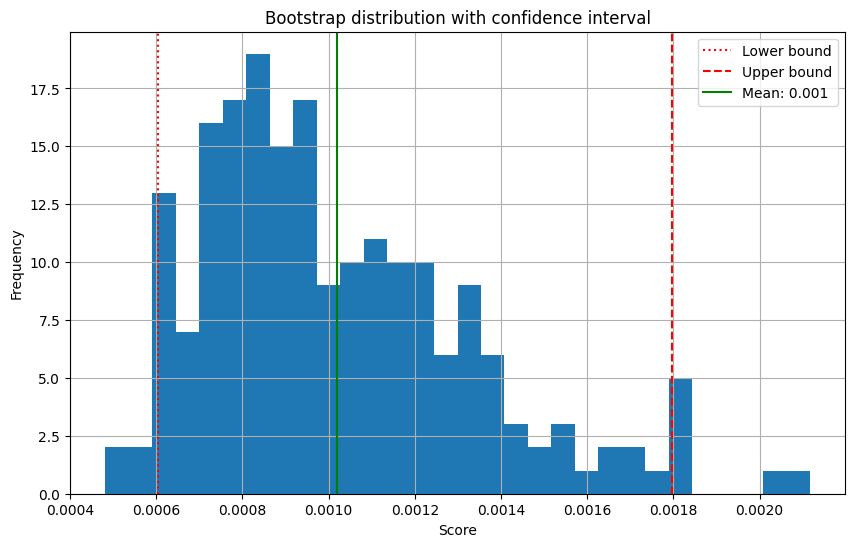

In [81]:
plt.figure(figsize=(10, 6))

# histogram of bootstrap scores
plt.hist(mse_score, bins=30)

# Add confidence interval lines
plt.axvline(ci_lower_mse, color='red', linestyle='dotted', label=f'Lower bound')
plt.axvline(ci_upper_mse, color='red', linestyle='dashed', label=f'Upper bound')
plt.axvline(np.mean(mse_score), color='green', label=f'Mean: {np.mean(mse_score):.3f}')

plt.xlabel('Score')
plt.ylabel('Frequency')
plt.title('Bootstrap distribution with confidence interval')
plt.grid()
plt.legend()
plt.show()